In [1]:
# Jika menjalankan di Google Colab, jalankan cell ini bila library belum tersedia.
!pip install -q numpy pandas scikit-learn matplotlib tensorflow


In [ ]:
# Tidak perlu mengunduh data AAPL dari Yahoo Finance karena tugas menggunakan dataset INCO.
# Upload file 'INCO (1).csv' ke folder kerja/Google Colab sebelum menjalankan cell berikutnya.


In [2]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense


data = pd.read_csv('INCO.csv')

# Dataset INCO memakai kolom 'date' dan 'close' (huruf kecil)
data['date'] = pd.to_datetime(data['date'], errors='coerce')
data['close'] = pd.to_numeric(data['close'], errors='coerce')
data = data.dropna(subset=['date', 'close']).sort_values('date').reset_index(drop=True)

dates = data['date']
prices = data[['close']].values.astype('float32')

# Membagi data berdasarkan urutan waktu: 67% data awal untuk training, sisanya untuk testing
train_size = int(len(prices) * 0.67)
look_back = 5

# Normalisasi: scaler dipelajari dari data training
scaler = MinMaxScaler(feature_range=(0, 1))
train_scaled = scaler.fit_transform(prices[:train_size])
all_scaled = scaler.transform(prices)

# Membuat urutan data: 5 hari sebelumnya digunakan untuk memprediksi hari berikutnya
def create_dataset(dataset, start_index, end_index, look_back=5):
    X, y, target_indices = [], [], []
    for i in range(max(start_index, look_back), end_index):
        X.append(dataset[i-look_back:i, 0])
        y.append(dataset[i, 0])
        target_indices.append(i)
    X = np.array(X, dtype=np.float32).reshape(-1, look_back, 1)
    y = np.array(y, dtype=np.float32).reshape(-1, 1)
    return X, y, np.array(target_indices)

train_X, train_y, _ = create_dataset(train_scaled, look_back, train_size, look_back)
test_X, test_y_scaled, test_indices = create_dataset(
    all_scaled, train_size, len(all_scaled), look_back
)
test_dates = dates.iloc[test_indices].reset_index(drop=True)
test_y = prices[test_indices]

print("Jumlah data:", len(prices))
print("Data training:", len(train_X))
print("Data testing:", len(test_X))
print("Periode data:", dates.min().date(), "sampai", dates.max().date())

def buat_model_lstm():
    model = Sequential([
        LSTM(4, input_shape=(look_back, 1)),
        Dense(1)
    ])
    model.compile(loss='mean_squared_error', optimizer='adam')
    return model

def latih_dan_prediksi(jumlah_epoch):
    # Membuat model baru untuk setiap percobaan
    tf.keras.backend.clear_session()
    tf.random.set_seed(42)
    model = buat_model_lstm()
    history = model.fit(
        train_X, train_y,
        epochs=jumlah_epoch,
        batch_size=1,
        verbose=2,
        shuffle=False
    )
    hasil_prediksi_scaled = model.predict(test_X, verbose=0)
    hasil_prediksi = scaler.inverse_transform(hasil_prediksi_scaled)
    harga_asli = scaler.inverse_transform(test_y_scaled)

    mae = mean_absolute_error(harga_asli, hasil_prediksi)
    rmse = np.sqrt(mean_squared_error(harga_asli, hasil_prediksi))
    print(f'\\nHasil model {jumlah_epoch} epoch')
    print(f'MAE  : {mae:.2f}')
    print(f'RMSE : {rmse:.2f}')
    return model, history, hasil_prediksi, harga_asli, mae, rmse

# Eksperimen pertama: 10 epoch
model_10, history_10, prediksi_10, harga_asli, mae_10, rmse_10 = latih_dan_prediksi(10)

# Eksperimen kedua: 100 epoch
model_100, history_100, prediksi_100, _, mae_100, rmse_100 = latih_dan_prediksi(100)

# Tabel ringkasan evaluasi
evaluasi = pd.DataFrame({
    'Model': ['LSTM 10 Epoch', 'LSTM 100 Epoch'],
    'MAE': [mae_10, mae_100],
    'RMSE': [rmse_10, rmse_100]
})
display(evaluasi)


Jumlah data: 1355
Data training: 902
Data testing: 448
Periode data: 2019-07-29 sampai 2025-02-21


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
902/902 - 5s - 6ms/step - loss: 0.0312
Epoch 2/10
902/902 - 3s - 3ms/step - loss: 0.0160
Epoch 3/10
902/902 - 3s - 3ms/step - loss: 0.0102
Epoch 4/10
902/902 - 3s - 3ms/step - loss: 0.0056
Epoch 5/10
902/902 - 3s - 4ms/step - loss: 0.0033
Epoch 6/10
902/902 - 3s - 4ms/step - loss: 0.0022
Epoch 7/10
902/902 - 3s - 4ms/step - loss: 0.0018
Epoch 8/10
902/902 - 3s - 4ms/step - loss: 0.0016
Epoch 9/10
902/902 - 3s - 4ms/step - loss: 0.0015
Epoch 10/10
902/902 - 3s - 3ms/step - loss: 0.0014
\nHasil model 10 epoch
MAE  : 599.28
RMSE : 674.86
Epoch 1/100


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


902/902 - 4s - 4ms/step - loss: 0.0038
Epoch 2/100
902/902 - 3s - 3ms/step - loss: 0.0016
Epoch 3/100
902/902 - 3s - 3ms/step - loss: 0.0015
Epoch 4/100
902/902 - 3s - 3ms/step - loss: 0.0014
Epoch 5/100
902/902 - 3s - 3ms/step - loss: 0.0014
Epoch 6/100
902/902 - 3s - 4ms/step - loss: 0.0014
Epoch 7/100
902/902 - 3s - 3ms/step - loss: 0.0013
Epoch 8/100
902/902 - 3s - 3ms/step - loss: 0.0013
Epoch 9/100
902/902 - 3s - 3ms/step - loss: 0.0013
Epoch 10/100
902/902 - 3s - 3ms/step - loss: 0.0012
Epoch 11/100
902/902 - 3s - 4ms/step - loss: 0.0012
Epoch 12/100
902/902 - 3s - 3ms/step - loss: 0.0012
Epoch 13/100
902/902 - 3s - 3ms/step - loss: 0.0011
Epoch 14/100
902/902 - 3s - 3ms/step - loss: 0.0011
Epoch 15/100
902/902 - 3s - 4ms/step - loss: 0.0011
Epoch 16/100
902/902 - 3s - 4ms/step - loss: 0.0010
Epoch 17/100
902/902 - 3s - 3ms/step - loss: 9.7512e-04
Epoch 18/100
902/902 - 3s - 4ms/step - loss: 9.3741e-04
Epoch 19/100
902/902 - 3s - 4ms/step - loss: 8.9954e-04
Epoch 20/100
902/902 

,Model,MAE,RMSE
0,LSTM 10 Epoch,599.276794,674.862532
1,LSTM 100 Epoch,270.299194,304.734695


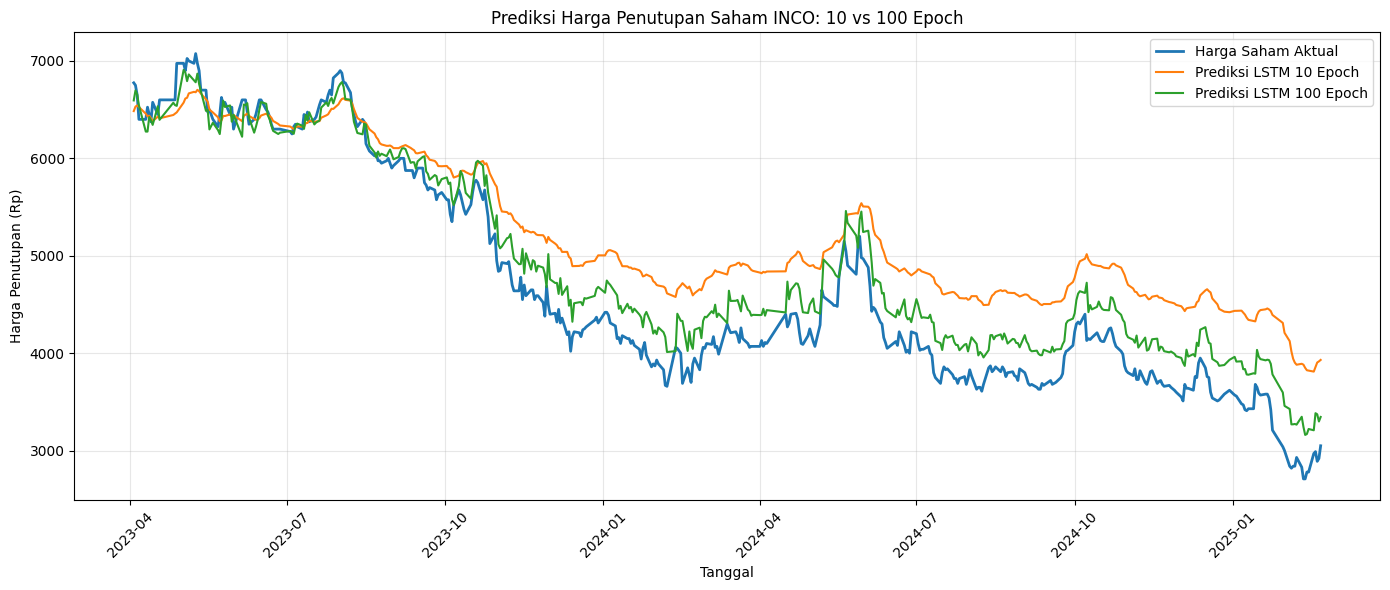

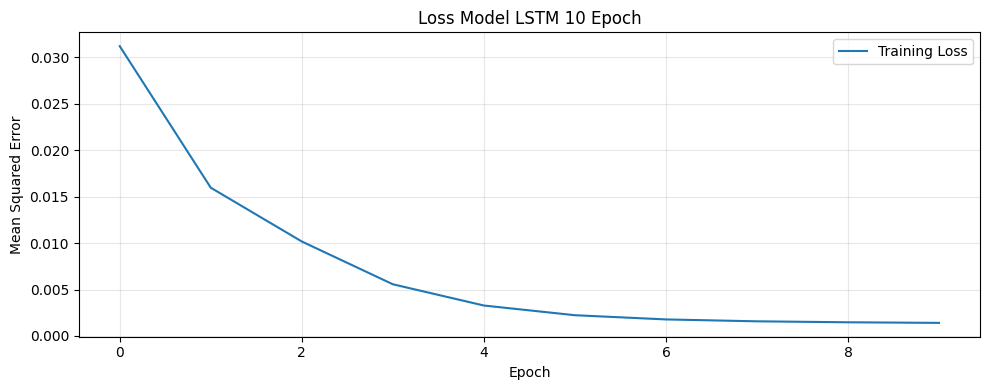

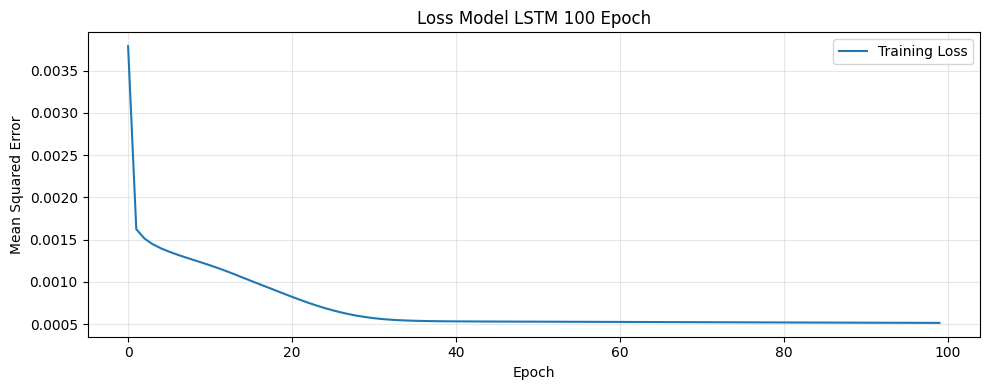

In [3]:
# Grafik perbandingan harga aktual dengan prediksi 10 dan 100 epoch
plt.figure(figsize=(14, 6))
plt.plot(test_dates, harga_asli.flatten(), label='Harga Saham Aktual', linewidth=2)
plt.plot(test_dates, prediksi_10.flatten(), label='Prediksi LSTM 10 Epoch')
plt.plot(test_dates, prediksi_100.flatten(), label='Prediksi LSTM 100 Epoch')
plt.title('Prediksi Harga Penutupan Saham INCO: 10 vs 100 Epoch')
plt.xlabel('Tanggal')
plt.ylabel('Harga Penutupan (Rp)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Grafik loss untuk model 10 epoch
plt.figure(figsize=(10, 4))
plt.plot(history_10.history['loss'], label='Training Loss')
plt.title('Loss Model LSTM 10 Epoch')
plt.xlabel('Epoch')
plt.ylabel('Mean Squared Error')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Grafik loss untuk model 100 epoch
plt.figure(figsize=(10, 4))
plt.plot(history_100.history['loss'], label='Training Loss')
plt.title('Loss Model LSTM 100 Epoch')
plt.xlabel('Epoch')
plt.ylabel('Mean Squared Error')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Interpretasi Hasil Prediksi Saham INCO Menggunakan LSTM

1. Interpretasi Model LSTM 10 Epoch

Berdasarkan grafik loss model LSTM dengan 10 epoch, terlihat bahwa nilai kesalahan pelatihan (*training loss*) mengalami penurunan dari awal hingga akhir proses pelatihan. Hal ini menunjukkan bahwa model mulai mempelajari pola dari data historis harga saham INCO. Namun, karena jumlah epoch relatif sedikit, proses pembelajaran model masih terbatas.

2. Interpretasi Model LSTM 100 Epoch

Pada grafik loss model LSTM dengan 100 epoch, terlihat bahwa nilai kesalahan pelatihan menurun cukup tajam pada tahap awal, kemudian semakin stabil. Hal ini menunjukkan bahwa model mempelajari pola data secara bertahap seiring bertambahnya jumlah epoch. Meskipun demikian, nilai training loss yang rendah belum tentu menjamin prediksi pada data pengujian lebih akurat.

3. Perbandingan Kedua Model

Model 10 epoch menjalani proses pelatihan yang lebih singkat, sedangkan model 100 epoch memiliki kesempatan belajar lebih banyak. Perbedaan kemampuan prediksi kedua model perlu dilihat dari grafik perbandingan harga aktual dengan harga prediksi serta nilai evaluasi MAE dan RMSE. Model dengan nilai MAE dan RMSE lebih rendah memiliki kesalahan prediksi yang lebih kecil pada data pengujian.

4. Kesimpulan

Berdasarkan hasil percobaan, metode LSTM dapat digunakan untuk mempelajari pola harga historis saham INCO. Penambahan jumlah epoch memengaruhi proses pembelajaran model, tetapi tidak selalu membuat prediksi menjadi lebih akurat. Oleh karena itu, hasil model 10 epoch dan 100 epoch perlu dibandingkan menggunakan grafik prediksi dan nilai MAE serta RMSE sebelum menentukan model yang memberikan hasil lebih baik.